# code_167 · Inspection bandits and delayed battery consequences

**Book:** section 32.1. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_32_GUIDE.md), [execution evidence](../CHAPTER_32_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_167).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Rewards, transitions, observation boundaries and independent assessment are defined below. Simulated rewards do not establish field safety or causal identification from arbitrary logs.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=5367;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 5367


<a id="contextual-inspection"></a>
 ## Learn from the inspection actually purchased
 A context contains a constant, a visible condition index and a visible access index. Three possible inspection types have different linear expected net benefits. LinUCB sees only the reward for its selected action, updates that action's ridge statistics, and retains the full selection log. The uniformly random and fixed-action controls are assessed on the same independent final contexts through conditional means, without simulated outcome noise. Potential rewards for actions not taken are available only inside the teaching simulator; no learner accesses them. Final contexts are independently generated after training; the fitted policy is frozen and compared through known conditional means, rather than selected on those means. Regret here uses the simulator's expected-reward oracle and is not available to a field agent.


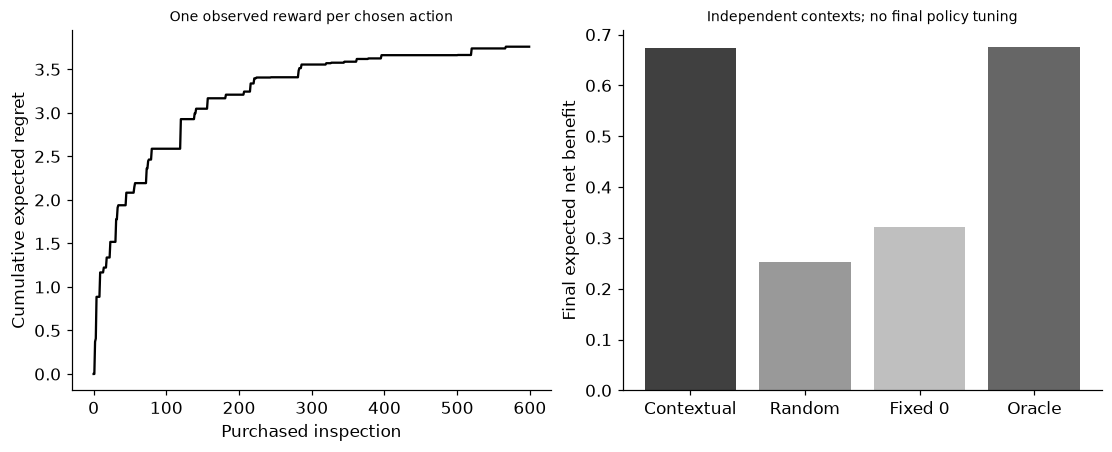

In [2]:
theta=np.array([[.30,.80,-.20],[.25,-.55,.45],[.20,.10,-.55]])
X=np.column_stack([np.ones(600),rng.uniform(-1,1,(600,2))]);noise=rng.normal(0,.15,(600,3));means=X@theta.T
A=np.repeat(np.eye(3)[None,:,:],3,axis=0);b=np.zeros((3,3));chosen=[];rewards=[];regrets=[];counts=np.zeros(3,int)
for t,x in enumerate(X):
    inv=np.linalg.inv(A);estimate=np.einsum('aij,aj->ai',inv,b);scores=estimate@x+.55*np.sqrt(np.einsum('i,aij,j->a',x,inv,x));action=int(scores.argmax());reward=means[t,action]+noise[t,action];A[action]+=np.outer(x,x);b[action]+=x*reward;chosen.append(action);rewards.append(float(reward));regrets.append(float(means[t].max()-means[t,action]));counts[action]+=1
final_x=np.column_stack([np.ones(400),rng.uniform(-1,1,(400,2))]);final_mean=final_x@theta.T;fitted=np.linalg.solve(A,b[:,:,None])[:,:,0];decision=(final_x@fitted.T).argmax(1);random_action=np.random.default_rng(SEED+1).integers(0,3,400)
final_values={'Frozen contextual':float(final_mean[np.arange(400),decision].mean()),'Uniform random':float(final_mean[np.arange(400),random_action].mean()),'Fixed inspection 0':float(final_mean[:,0].mean()),'Context oracle':float(final_mean.max(1).mean())}
assert counts.sum()==600 and len(rewards)==600 and np.isfinite(fitted).all();assert final_values['Context oracle']>=max(final_values.values())-1e-12
RESULTS.update(training_decisions=600,observed_training_rewards=600,final_contexts=400,final_feedback_used_for_learning=0,ucb_coefficient=.55,action_counts=counts.tolist(),training_pseudo_regret=float(sum(regrets)),final_expected_reward=final_values,source_action_reward_log=[{'t':i,'action':chosen[i],'reward':rewards[i]} for i in range(5)])
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(np.cumsum(regrets),color='black');axes[0].set(xlabel='Purchased inspection',ylabel='Cumulative expected regret',title='One observed reward per chosen action');axes[1].bar(range(4),list(final_values.values()),color=['.25','.6','.75','.4']);axes[1].set(xticks=range(4),xticklabels=['Contextual','Random','Fixed 0','Oracle'],ylabel='Final expected net benefit',title='Independent contexts; no final policy tuning');plt.show()


<a id="sequential-feedback-and-aliasing"></a>
 ## A battery changes tomorrow's feasible decision
 A unit-capacity, lossless teaching battery starts full. It can discharge one unit now at price 0.2, or keep it for the final period at price 1.0. Exact backward induction values stored energy; immediate-reward greed empties it too early. There is no terminal salvage. If the next price can instead be 0.05, the same present observation (full battery and price 0.2) conceals two different optimal decisions unless the price regime is observed or inferred. A contextual inspection model is appropriate only while inspection has no effect on later action sets or information value; an inspection that triggers repair or reveals a persistent hidden state is sequential.


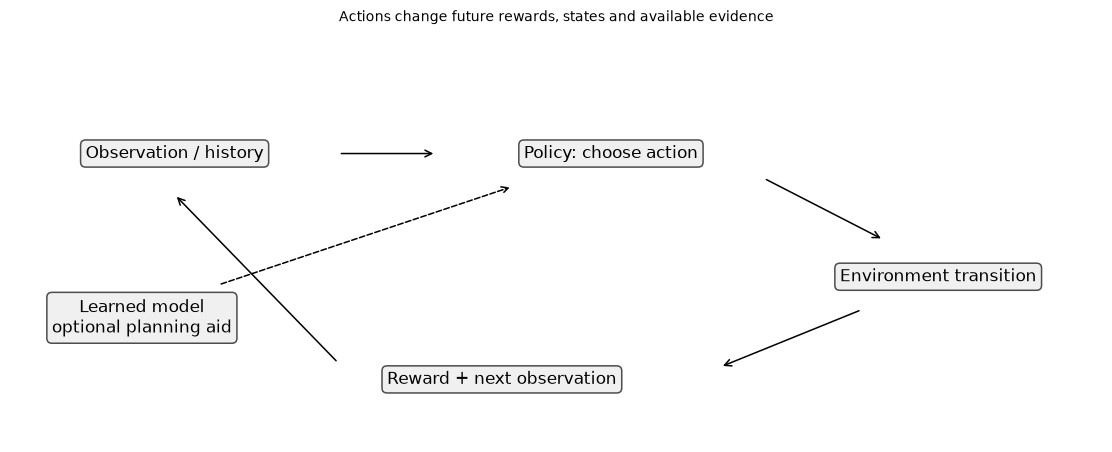

In [3]:
def battery_plan(prices):
    V=np.zeros((len(prices)+1,2));policy=np.zeros((len(prices),2),int)
    for t in reversed(range(len(prices))):
        for storage in [0,1]:
            options=[prices[t]*a+V[t+1,storage-a] for a in range(storage+1)];policy[t,storage]=int(np.argmax(options));V[t,storage]=max(options)
    storage=1;trace=[]
    for t,price in enumerate(prices):
        a=int(policy[t,storage]);trace.append({'t':t,'storage_before':storage,'price':price,'discharge':a,'reward':float(price*a)});storage-=a
    return float(V[0,1]),trace
optimal,trace=battery_plan([.2,1.]);low_future,low_trace=battery_plan([.2,.05]);myopic=.2
assert optimal==1. and myopic<optimal and trace[0]['discharge']==0 and low_trace[0]['discharge']==1
RESULTS.update(battery_optimal_return=optimal,battery_myopic_return=myopic,battery_trace=trace,aliased_first_actions={'high_future_price':trace[0]['discharge'],'low_future_price':low_trace[0]['discharge']})
fig,ax=plt.subplots(figsize=(10,4));ax.axis('off');boxes=[(.15,.7,'Observation / history'),(.55,.7,'Policy: choose action'),(.85,.4,'Environment transition'),(.45,.15,'Reward + next observation'),(.12,.3,'Learned model\noptional planning aid')]
for x,y,label in boxes:ax.text(x,y,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round','facecolor':'.94','edgecolor':'.3'})
for start,end in [((.30,.7),(.39,.7)),((.69,.64),(.80,.49)),((.78,.32),(.65,.18)),((.30,.19),(.15,.60))]:ax.annotate('',xy=end,xytext=start,xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'black'})
ax.annotate('',xy=(.46,.62),xytext=(.19,.38),xycoords='axes fraction',arrowprops={'arrowstyle':'->','linestyle':'--'});ax.set_title('Actions change future rewards, states and available evidence');plt.show()


In [4]:
summary={'example_id':'code_167','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual contextual linear upper-confidence acquisition with chosen-action feedback', 'independent fixed-policy evaluation against contextual expected-reward oracle', 'exact two-step battery dynamic program versus myopic reward', 'aliased observations under partial observability', 'agent environment feedback with policy and model distinguished'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual contextual linear upper-confidence acquisition with chosen-action feedback", "independent fixed-policy evaluation against contextual expected-reward oracle", "exact two-step battery dynamic program versus myopic reward", "aliased observations under partial observability", "agent environment feedback with policy and model distinguished"], "elapsed_seconds": 0.461, "example_id": "code_167", "hardware": "Darwin arm64 CPU", "results": {"action_counts": [260, 229, 111], "aliased_first_actions": {"high_future_price": 0, "low_future_price": 1}, "battery_myopic_return": 0.2, "battery_optimal_return": 1.0, "battery_trace": [{"discharge": 0, "price": 0.2, "reward": 0.0, "storage_before": 1, "t": 0}, {"discharge": 1, "price": 1.0, "reward": 1.0, "storage_before": 1, "t": 1}], "final_contexts": 400, "final_expected_reward": {"Context oracle": 0.674585935480358, "Fixed inspection 0": 0.32115802258857834, "Frozen contextual": 0.67417518832793